# Thông tin sinh viên

*   MSSV: xxxxxxx
*   Họ và tên: xxxxxxx



#Bài tập 8: Phân đoạn ảnh

#Kết nối/ Mount đến Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Khai báo thư viện

In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from google.colab.patches import cv2_imshow

# Đọc dữ liệu

In [4]:
img_folder  = "/content/drive/MyDrive/CS231/Baitap8/images"

#Thực hiện yêu cầu 1:
Áp dụng phân đoạn ảnh sử dụng phương pháp lấy ngưỡng cho các ảnh sau:
* particles.bmp
* Phandoan01.jpg
* wdg2.jpg
* Rice.png

In [5]:
def drawHist(x):
  hist = cv2.calcHist([x], [0], None, [256], [0, 256])
  plt.plot(hist)
  plt.xlim([0, 256])
  plt.legend(('histogram'), loc = 'upper left')
  plt.show()

In [6]:
def globalThresholding(img, thres=127):
  img_rst = img.copy()
  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      if img_rst[i][j] < thres:
        img_rst[i][j] = 255
      else:
        img_rst[i][j] = 0
  return img_rst

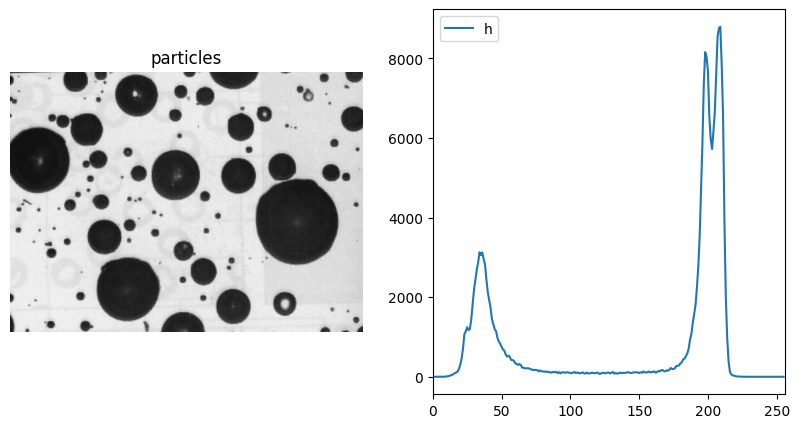

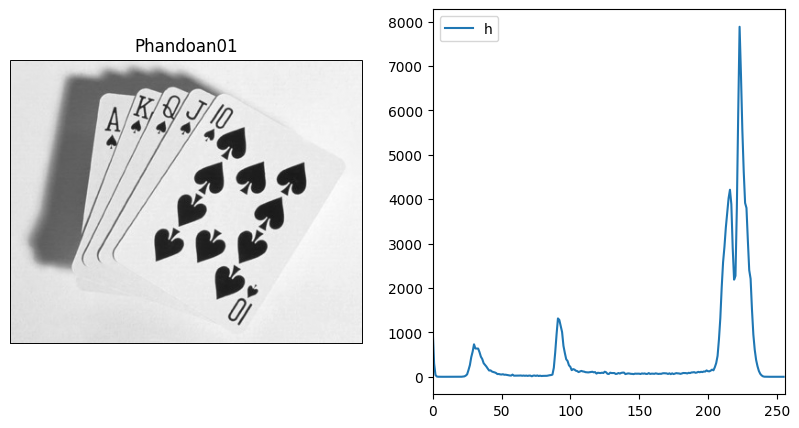

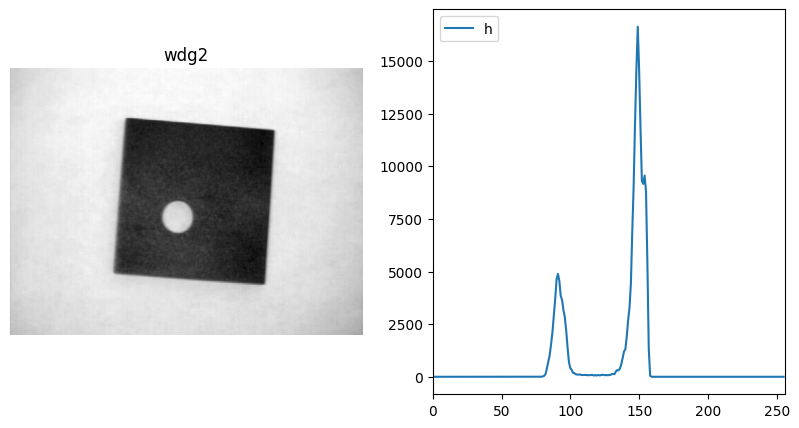

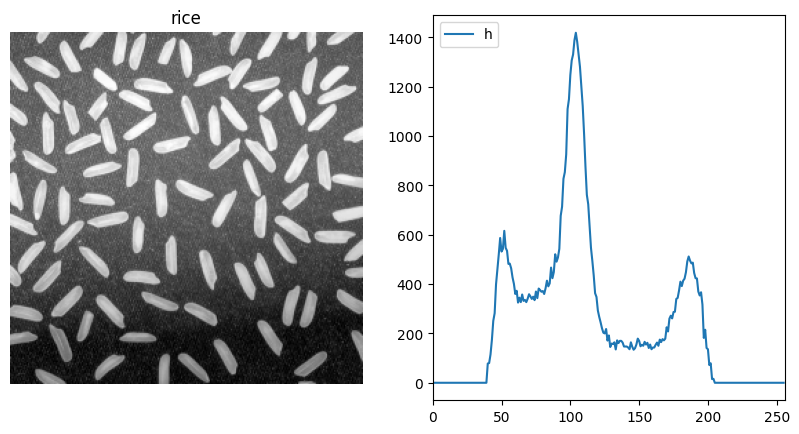

In [7]:
file_names = ['particles.bmp','Phandoan01.jpg', 'wdg2.jpg', 'rice.png']

for file_name in file_names:
  img_path= os.path.join(img_folder, file_name)
  image=cv2.imread(img_path,0)
  #image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

  plt.figure(figsize=(10, 5))

  # Vẽ hình ảnh
  plt.subplot(1, 2, 1)  # 1 hàng, 2 cột, subplot 1
  plt.imshow(image, cmap=plt.cm.gray)
  plt.title(file_name.split('.')[0])
  plt.axis('off')

  # Vẽ biểu đồ
  plt.subplot(1, 2, 2)  # 1 hàng, 2 cột, subplot 2
  drawHist(image)

  plt.show()

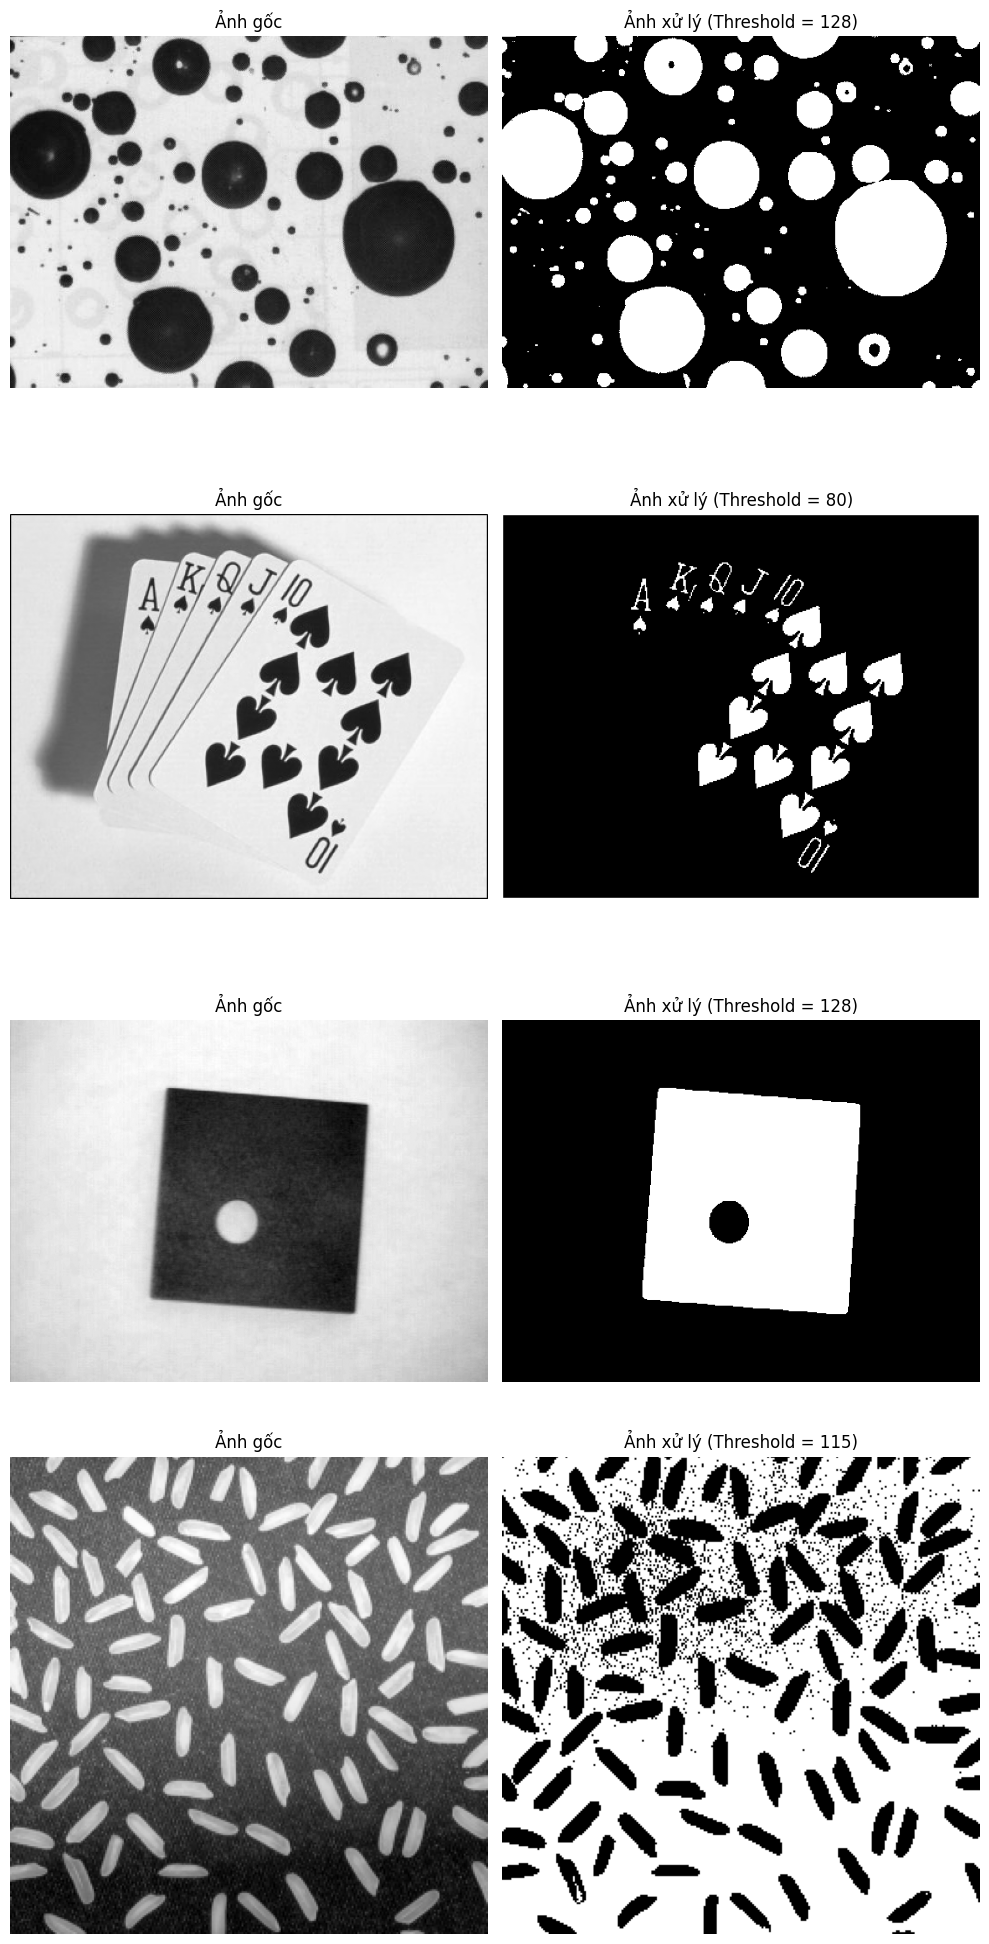

In [8]:
pic_threshold = [128, 80, 128, 115]

num_rows = 4
num_cols = 2

# Tạo subplots
fig, axes = plt.subplots(num_rows, num_cols, figsize=(10, 5*4))

for i, file_name in enumerate(file_names):
    img_path= os.path.join(img_folder, file_name)
    img= cv2.imread(img_path,0)
    img_globalThreshold = globalThresholding(img, pic_threshold[i] )

    #Show ảnh gốc
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_title('Ảnh gốc')
    axes[i, 0].axis('off')

    #Ảnh qua xử lý
    axes[i, 1].imshow(img_globalThreshold, cmap='gray')
    axes[i, 1].set_title(f'Ảnh xử lý (Threshold = {pic_threshold[i]})' )
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

# Yêu cầu 2: Áp dụng kmeans để phân đoạn ảnh
* hand.jpg,
* Mai01.png
* Dao04.png



In [9]:
def kmeans_segemtation(image_path, k):
  # Đọc ảnh
  image = cv2.imread(image_path)
  image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # Chuyển ảnh từ BGR sang RGB

  # Chuyển ảnh thành mảng 2D
  pixels = image.reshape((-1, 3)) # Mỗi pixel có 3 giá trị màu (R, G, B)
  # Áp dụng K-Means Clustering
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(pixels)
  # Lấy nhãn của từng pixel
  segmented_img = kmeans.cluster_centers_[kmeans.labels_]
  # Chuyển đổi về dạng ảnh
  segmented_img = segmented_img.reshape(image.shape).astype(np.uint8)
  return image, segmented_img


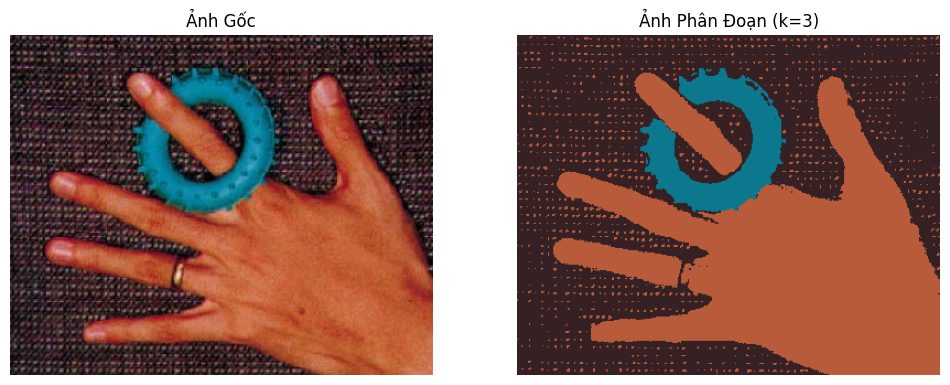

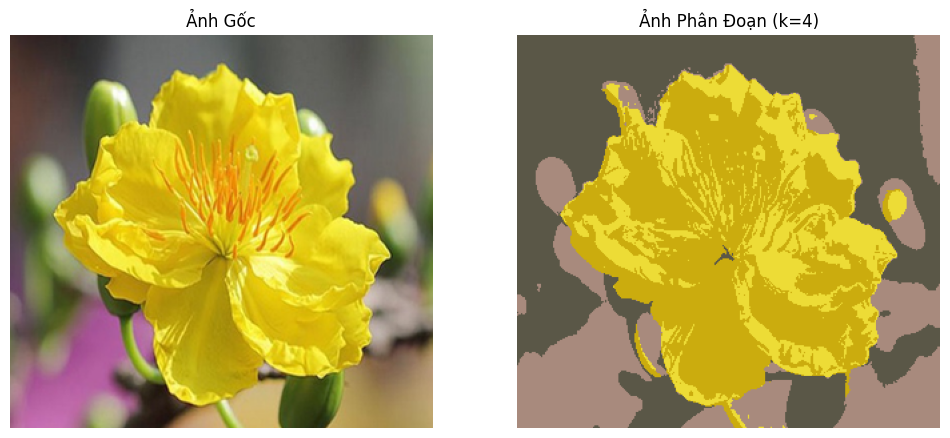

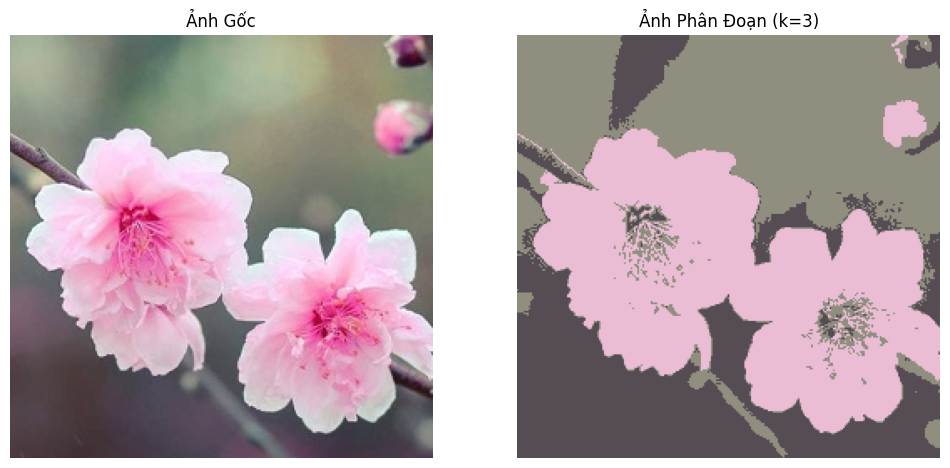

In [10]:
file_names = ['hand.jpg','Mai01.png','Dao04.png']
img_n_clusters = [3, 4, 3]

for i, file_name in enumerate(file_names):
  image_path = os.path.join(img_folder, file_name)
  image, segmented_img = kmeans_segemtation(image_path, img_n_clusters[i])
  # Hiển thị ảnh gốc và ảnh đã phân đoạn
  fig, axes = plt.subplots(1, 2, figsize=(12, 6))
  axes[0].imshow(image)
  axes[0].set_title("Ảnh Gốc")
  axes[0].axis("off")
  axes[1].imshow(segmented_img)
  axes[1].set_title(f"Ảnh Phân Đoạn (k={img_n_clusters[i]})")
  axes[1].axis("off")
  plt.show()